<a href="https://colab.research.google.com/github/123-aishwarya/analysing-pharmaceutical-sales-data/blob/main/pharma_sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

# Load the dataset uploaded to Colab
df = pd.read_csv("salesdaily.csv")

# 1. Inspect rows, columns, and data types
print("Shape (rows, columns):", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nColumn names and types:")
print(df.info())

# 2. Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 3. Convert date column and extract year and month
# Adjust 'datum' if your file uses a different date column name
date_col = "datum" if "datum" in df.columns else df.columns[0]
df[date_col] = pd.to_datetime(df[date_col])
df["year"] = df[date_col].dt.year
df["month"] = df[date_col].dt.month

print("\nDate range:", df[date_col].min(), "to", df[date_col].max())

Shape (rows, columns): (2106, 13)

First 5 rows:
      datum  M01AB  M01AE  N02BA  N02BE  N05B  N05C   R03  R06  Year  Month  \
0  1/2/2014    0.0   3.67    3.4  32.40   7.0   0.0   0.0  2.0  2014      1   
1  1/3/2014    8.0   4.00    4.4  50.60  16.0   0.0  20.0  4.0  2014      1   
2  1/4/2014    2.0   1.00    6.5  61.85  10.0   0.0   9.0  1.0  2014      1   
3  1/5/2014    4.0   3.00    7.0  41.10   8.0   0.0   3.0  0.0  2014      1   
4  1/6/2014    5.0   1.00    4.5  21.70  16.0   2.0   6.0  2.0  2014      1   

   Hour Weekday Name  
0   248     Thursday  
1   276       Friday  
2   276     Saturday  
3   276       Sunday  
4   276       Monday  

Column names and types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2106 entries, 0 to 2105
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   datum         2106 non-null   object 
 1   M01AB         2106 non-null   float64
 2   M01AE         2106 non-null  

Top 10 drugs by total sales:
N02BE    63005.402708
N05B     18645.737500
R03      11608.822917
M01AB    10600.937083
M01AE     8204.618646
N02BA     8172.209000
R06       6107.817500
N05C      1249.958333
dtype: float64


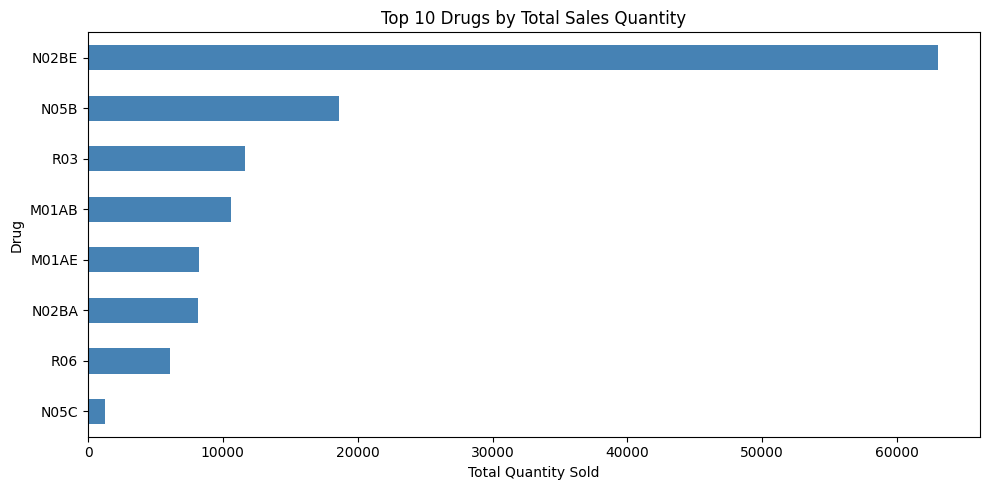

In [11]:
# Identify numeric drug quantity columns (exclude calendar/helper columns)
exclude_cols = {"datum", "Year", "Month", "Hour", "Weekday Name", "year", "month"}
drug_cols = [
    col
    for col in df.select_dtypes(include="number").columns
    if col not in exclude_cols
]

# Total sales per individual drug / column
brand_totals = df[drug_cols].sum().sort_values(ascending=False)
print("Top 10 drugs by total sales:")
print(brand_totals.head(10))

# Plot top 10 individual drugs
plt.figure(figsize=(10, 5))
brand_totals.head(10).sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 10 Drugs by Total Sales Quantity")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Drug")
plt.tight_layout()
plt.show()

In [12]:
windows = [
    ("January 2015", 2015, 1),
    ("July 2016", 2016, 7),
    ("September 2017", 2017, 9),
]

for label, yr, mo in windows:
  subset = df[(df["year"] == yr) & (df["month"] == mo)]
  top3 = subset[drug_cols].sum().sort_values(ascending=False).head(3)
  print(f"\nTop 3 drugs in {label}:")
  print(top3)


Top 3 drugs in January 2015:
N02BE    1044.24
N05B      463.00
R03       177.25
dtype: float64

Top 3 drugs in July 2016:
N02BE    652.362000
N05B     240.000000
M01AB    194.528333
dtype: float64

Top 3 drugs in September 2017:
N02BE    863.75
N05B     223.00
R03      139.00
dtype: float64


In [13]:
df_2017 = df[df["year"] == 2017]

# Count how many records had sales > 0 in 2017
sales_frequency_2017 = (df_2017[drug_cols] > 0).sum().sort_values(ascending=False)
print("Most frequently sold drugs in 2017 (count of days with sales > 0):")
print(sales_frequency_2017.head(5))

# Average daily sales across daily rows
avg_daily_sales = df[drug_cols].mean().sort_values(ascending=False)
print("\nHighest average daily sales:")
print(avg_daily_sales.head(5))

Most frequently sold drugs in 2017 (count of days with sales > 0):
N02BE    361
M01AB    360
M01AE    360
N05B     356
N02BA    350
dtype: int64

Highest average daily sales:
N02BE    29.917095
N05B      8.853627
R03       5.512262
M01AB     5.033683
M01AE     3.895830
dtype: float64


R03 columns found: ['R03']


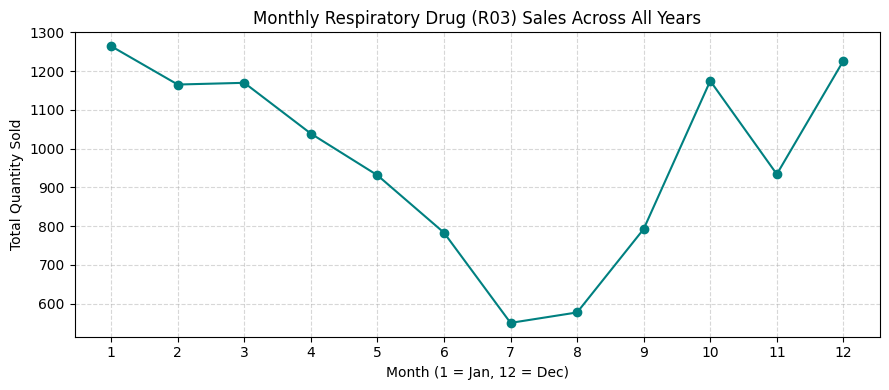

In [14]:
r03_cols = [col for col in drug_cols if col.startswith("R03")]
print("R03 columns found:", r03_cols)

r03_monthly = df.groupby("month")[r03_cols].sum().sum(axis=1)

plt.figure(figsize=(9, 4))
r03_monthly.plot(kind="line", marker="o", color="teal")
plt.title("Monthly Respiratory Drug (R03) Sales Across All Years")
plt.xlabel("Month (1 = Jan, 12 = Dec)")
plt.ylabel("Total Quantity Sold")
plt.xticks(range(1, 13))
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()